In [1]:
# note that the order of points in GeoPandas is longitude, latitude
# (opposite order from that of many data sets)

import geopandas
import shapely.geometry
import shapely.ops
import pyproj
import pandas as pd

import time
import numpy as np
!pip install cartopy

#import pygsheets not used in Scott's method
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.patches
import matplotlib.lines
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import matplotlib.image as mpimg  # Correct import for image handling
from matplotlib.font_manager import fontManager, FontProperties


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 35.6 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
GOGET_Map_folder = '/content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/Reports/Q1 2025 GOGET Report/GOGET Maps Files/'
NE_folder = GOGET_Map_folder + 'Natural_Earth_quick_start/'
Data = '/content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/Reports/Q1 2026 GOGET briefing/Data Viz/Data/'

In [4]:
# Path to your font file
font_path = GOGET_Map_folder + 'OpenSans-Regular.ttf'  # Update this to the path where the font file is located

# Add the font to Matplotlib's font manager
fontManager.addfont(font_path)

In [5]:
# set output path
output_path = '/content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/Reports/Q1 2026 GOGET briefing/Data Viz/Drafts/'

In [6]:
# gemplot variables
footer_color = "#222222"
footer_lineheight = 1.2
footer_fontsize = 14

base_ratio = 1.0
base_size = base_ratio * 16
color_title = "#222222"
color_subtitle = "#333333"
color_grid = "#cbcbcb"

text_weight_normal = 400
text_weight_bold = 700

In [7]:
# logo and note (assuming stays the same)
gem_logo_path = GOGET_Map_folder +'/gem_logo_padding.png'
note_text='Source: Global Oil and Gas Extraction Tracker, March 2026'

def add_logo_and_note(ax,
                      note_text='Source: Global Oil and Gas Extraction Tracker, March 2026',
                      logo_zoom=0.025, logo_coords=(1, 0), logo_box_alignment=(1, 1),
                      note_x=0, note_y=-.1, note_fontsize=8, note_color='#525252',
                      linespacing=1.2):
    """
    Adds a logo and a note to the specified axis.

    Parameters:
    ax : matplotlib.axes.Axes
        The axis to which the logo and note will be added.
    logo_path : str, optional
        Path to the logo image file. Default is 'gem_logo_padding.png'.
    note_text : str, optional
        The text to display as a note. Default is 'Source: Global Oil and Gas Extraction Tracker, February 2025'.
    logo_zoom : float, optional
        Zoom factor for the logo image. Default is 0.025.
    logo_coords : tuple, optional
        Coordinates of the logo in axes fraction. Default is (1, 0).
    logo_box_alignment : tuple, optional
        Alignment of the logo box. Default is (1, 1.25).
    note_x : float, optional
        X-coordinate of the note text. Default is 0.
    note_y : float, optional
        Y-coordinate of the note text. Default is -0.16.
    note_fontsize : int, optional
        Font size for the note text. Default is 10.
    note_color : str, optional
        Color of the note text. Default is 'black'.
    linespacing : float, optional
        Line spacing for the note text. Default is 1.2.
    """
    # Add the logo
    try:
        gem_logo = mpimg.imread(gem_logo_path)
        logo_image_box = OffsetImage(gem_logo, zoom=logo_zoom)
        logo_annotation_box = AnnotationBbox(logo_image_box, logo_coords,
                                             xycoords='axes fraction',
                                             box_alignment=logo_box_alignment,
                                             frameon=False)
        ax.add_artist(logo_annotation_box)
    except FileNotFoundError:
        print(f"Error: Logo file not found at {logo_path}")

    # Add the note
    ax.text(x=note_x, y=note_y, s=note_text,
            fontsize=note_fontsize, color=note_color,
            transform=ax.transAxes, ha='left', va='center',
            linespacing=linespacing)


In [8]:
# load in data
data_file = 'discovery_start_years 2026 01 30 - Eras.csv'
df = pd.read_csv(Data + data_file)


In [9]:
# define GEM palette
gem_palette = [
    "#BF532C", # brown
    "#F27D16", # orange
    "#4F408C", # purple
    "#457BD1", # blue
    "#5F9E79", # green
    "#D9D9D9"  # grey
]

filtered out 0 rows


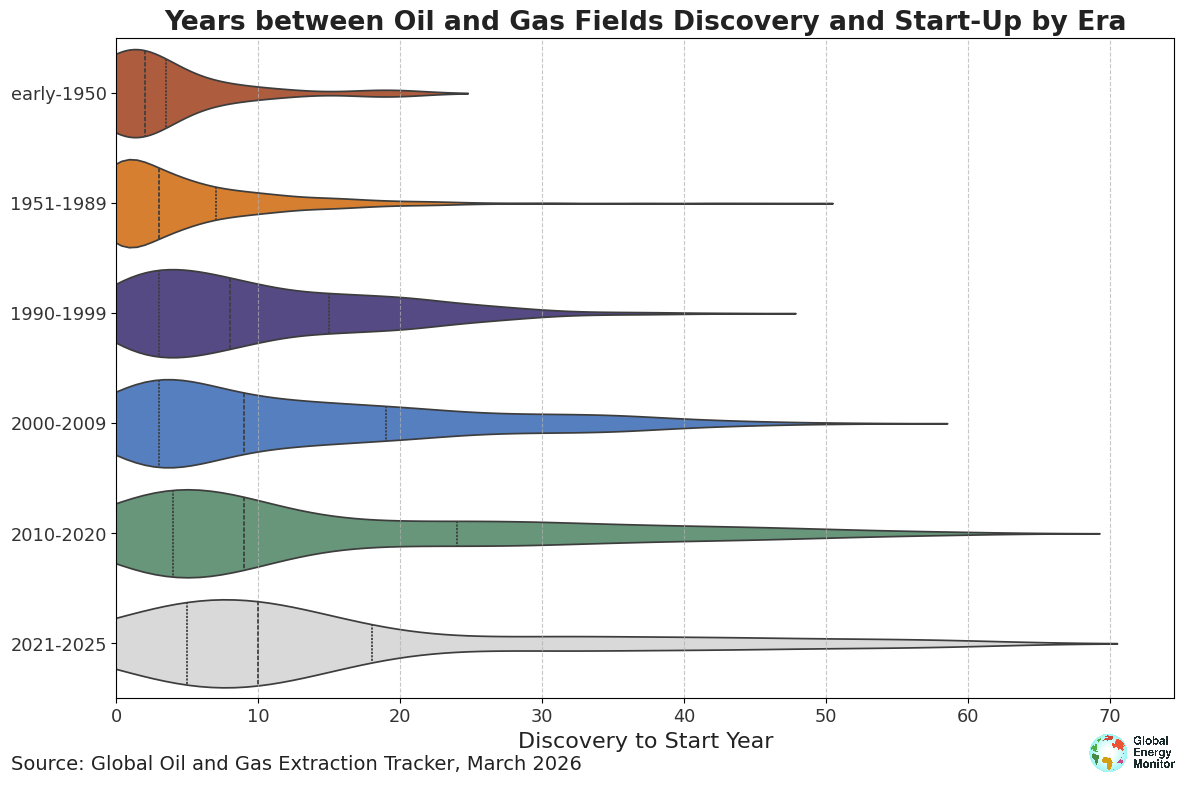

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define GEM palette (moved here to ensure it's always available)
gem_palette = [
    "#BF532C", # brown
    "#F27D16", # orange
    "#4F408C", # purple
    "#457BD1", # blue
    "#5F9E79", # green
    "#D9D9D9"  # grey
]

# Ensure these columns exist, if not, an error will occur
# and I will then inspect the dataframe columns.
if 'Era' not in df.columns:
    print("Error: 'Era' column not found in DataFrame.")
elif 'Discovery to Start Year' not in df.columns:
    print("Error: 'Discovery to Start Year' column not found in DataFrame.")
else:
    # Filter out rows where 'Discovery to Start Year' is negative
    df_filtered_for_plot = df[df['Discovery to Start Year'] >= 0]

    # print how many rows were filtered out
    print (f'filtered out {len(df_filtered_for_plot)-len(df)} rows') # Changed .len to len()

    # # filter out early 1950s and 1951-1981 era
    # df_filtered_for_plot = df_filtered_for_plot[~((df_filtered_for_plot['Era'] == 'early-1950') | (df_filtered_for_plot['Era'] == '1951-1989'))]

    plt.figure(figsize=(12, 8))
    # Using violinplot to show distribution more clearly and avoid point overlap
    sns.violinplot(data=df_filtered_for_plot, x='Discovery to Start Year', y='Era', hue='Era', palette=gem_palette, inner='quartile', legend=False)
    plt.title('Years between Oil and Gas Fields Discovery and Start-Up by Era', fontsize=base_size * 1.2, color=color_title, weight=text_weight_bold)
    plt.xlabel('Discovery to Start Year', fontsize=base_size, color=color_title)
    plt.ylabel('') # Removed y-axis label
    plt.xticks(fontsize=base_size * 0.8, color=color_subtitle)
    plt.yticks(fontsize=base_size * 0.8, color=color_subtitle)
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    # Set x-axis limit to start from 0
    plt.xlim(left=0)

    # Add the logo and note
    ax = plt.gca() # Get current axes
    add_logo_and_note(ax, note_text=note_text, note_fontsize=footer_fontsize, note_color=footer_color, linespacing=footer_lineheight, note_x=-.1, logo_coords=(1, -0.05)) # Adjusted logo_coords y-value

    plt.tight_layout()

    # Moved savefig calls here, before plt.show()
    timestamp = time.strftime("%Y-%m-%d")
    str_timestamp = str(timestamp)
    plt.savefig(output_path + f'discovery_to_start_year_violins {str_timestamp}.png')
    plt.savefig(output_path + f'discovery_to_start_year_violins {str_timestamp}.svg')

    plt.show()

In [11]:
# create time stamp
timestamp = time.strftime("%Y-%m-%d")
str_timestamp = str(timestamp)

# The savefig calls should be placed before plt.show() in the plotting cell
# This cell will now be empty as the save logic moves to the plot generation cell.

In [ ]:
print(df.columns)

Index(['unit_id', 'Name', 'Discovery Year', 'Start Year',
       'Discovery to Start Year', 'Era', 'Type'],
      dtype='object')
